Saving CCA_Dataset.csv to CCA_Dataset.csv
         X1         X2        X3        X4        Y1        Y2         Y3
0  1.971241   6.702125  0.410195 -2.712593 -0.770524 -3.062638   2.764469
1  0.815338   7.985222  1.576354 -2.406596 -3.673239 -4.694017  14.104524
2 -0.693237   9.655552 -0.566316  1.079341  0.162747 -0.323253   0.121652
3 -0.006933   0.327976  0.211015  0.839060 -0.323253  0.198880  -0.391015
4 -4.003556  11.034649 -1.420485  2.673175  3.537477  1.554290  -1.351532
5  0.321971  -6.818027 -0.975308 -0.039113 -1.435207  1.886911  -3.550842
6  3.149302  -4.244258  1.330710 -1.918998 -2.501693 -2.921395   3.870522
7  0.641964   1.366539  0.533052 -0.787973 -0.939810 -0.732898  -2.359760
8  1.758616  -3.992942  0.862967 -3.431079 -2.515359 -1.021398   4.639580
9  0.443252  -1.753928  0.247372 -1.139232 -1.784406 -0.946722  -0.581214
Shape: (240, 7)
Columns: Index(['X1', 'X2', 'X3', 'X4', 'Y1', 'Y2', 'Y3'], dtype='object')
               X1          X2          X3          X4

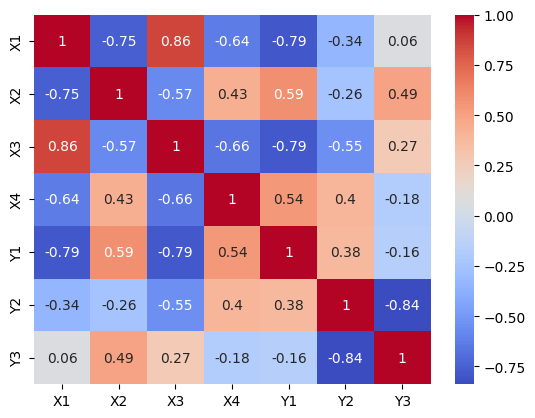

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import CCA
from sklearn.model_selection import train_test_split

# Upload CSV in Google Colab
from google.colab import files
uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

print(df.head(10))
print("Shape:", df.shape)
print("Columns:", df.columns)
print(df.describe())
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

X = df[['X1', 'X2', 'X3', 'X4']]
Y = df[['Y1', 'Y2', 'Y3']]

sns.heatmap(df[['X1','X2','X3','X4','Y1','Y2','Y3']].corr(),
            annot=True, cmap='coolwarm')
plt.show()

Cross-set correlation:
 X1   -0.790248
X2    0.587891
X3   -0.786104
X4    0.542177
dtype: float64


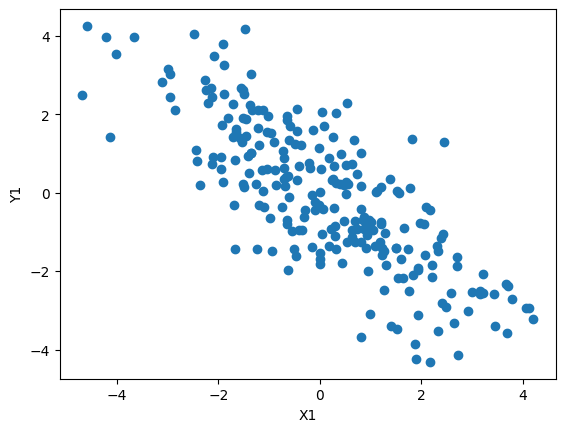

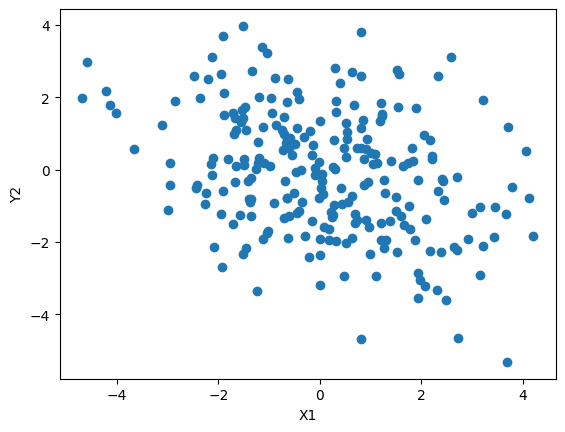

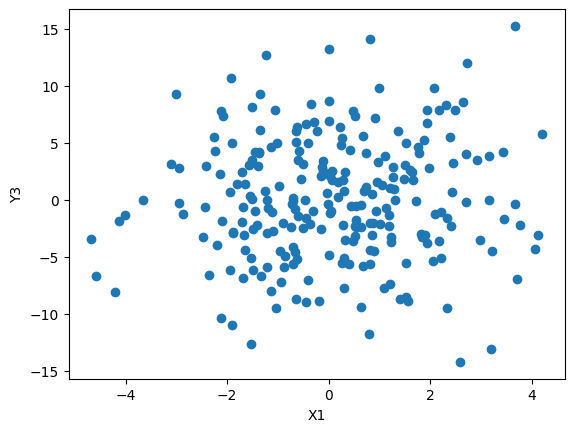

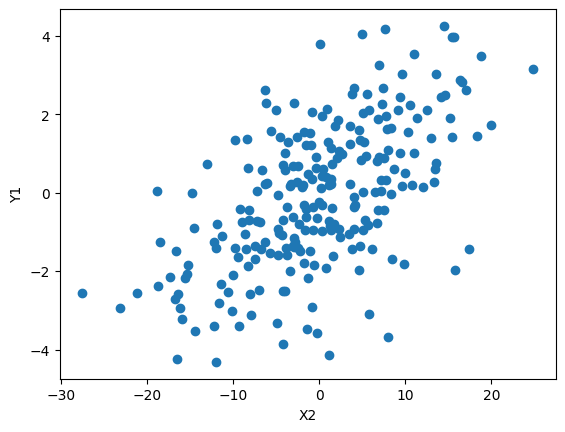

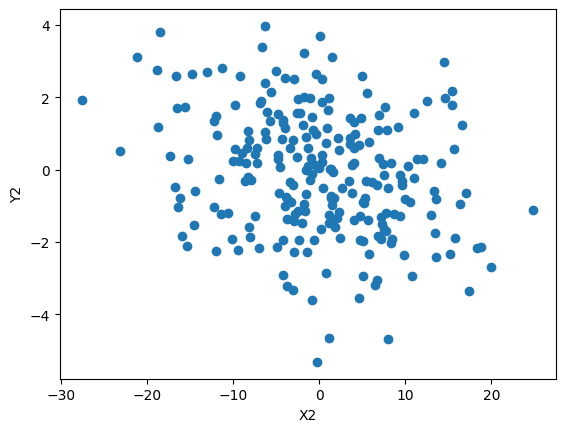

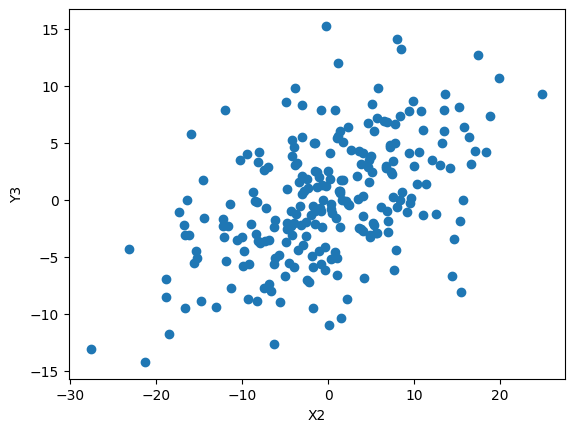

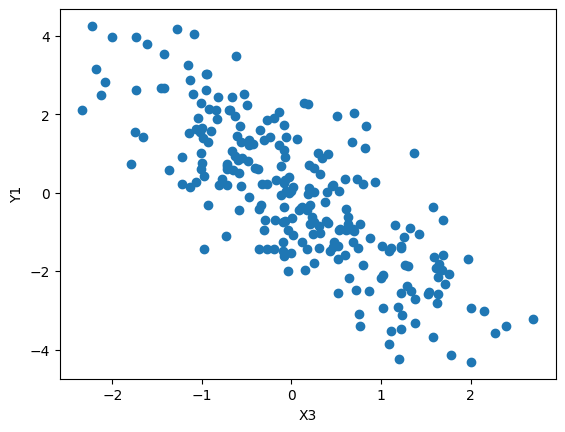

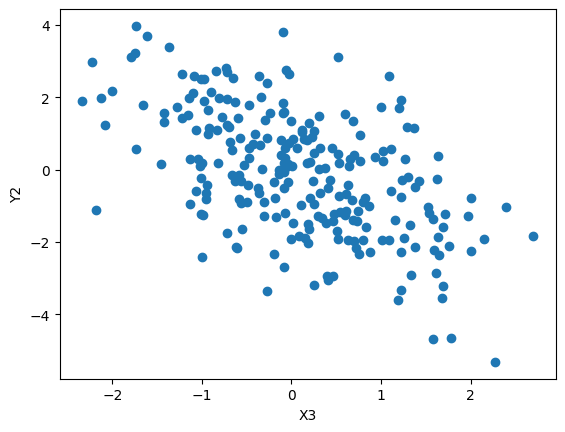

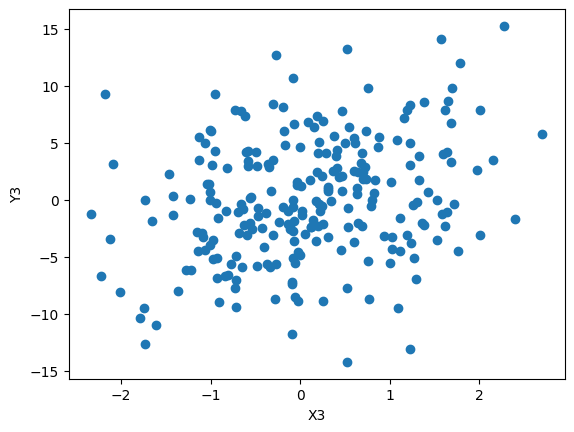

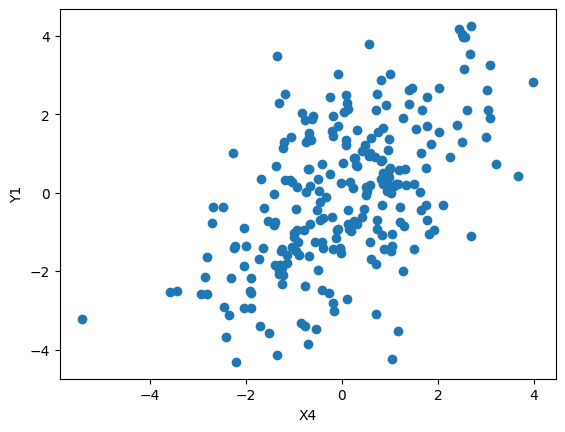

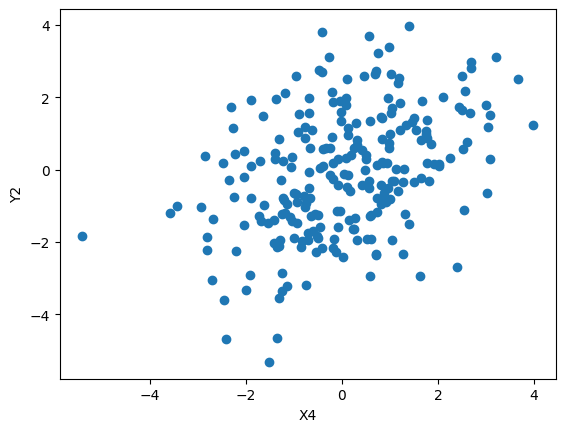

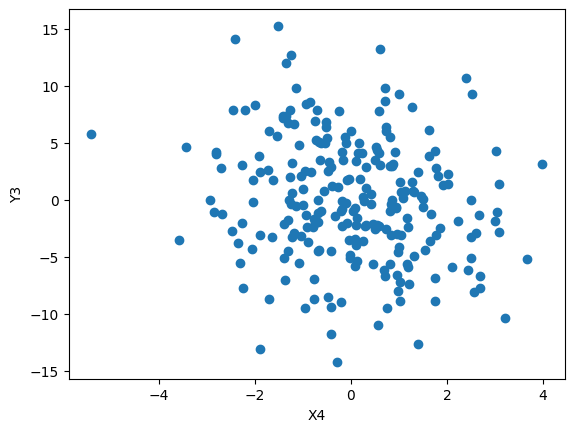

In [ ]:
print("Cross-set correlation:\n", X.corrwith(Y['Y1']))

for x in X.columns:
    for y in Y.columns:
        plt.scatter(df[x], df[y])
        plt.xlabel(x)
        plt.ylabel(y)
        plt.show()

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.3, random_state=42
)

sx = StandardScaler()
sy = StandardScaler()

X_train = sx.fit_transform(X_train)
X_test = sx.transform(X_test)

Y_train = sy.fit_transform(Y_train)
Y_test = sy.transform(Y_test)

cca = CCA(n_components=3, max_iter=1000)
cca.fit(X_train, Y_train)

X_train_c, Y_train_c = cca.transform(X_train, Y_train)
X_test_c, Y_test_c = cca.transform(X_test, Y_test)

train_corr = []
test_corr = []

for i in range(3):
    train_corr.append(np.corrcoef(X_train_c[:, i], Y_train_c[:, i])[0, 1])
    test_corr.append(np.corrcoef(X_test_c[:, i], Y_test_c[:, i])[0, 1])

print("Training correlations:", train_corr)
print("Testing correlations:", test_corr)

Training correlations: [np.float64(0.9151565653060538), np.float64(0.8271554375145934), np.float64(0.14408729363786485)]
Testing correlations: [np.float64(0.9238458004350002), np.float64(0.8285070835321344), np.float64(-0.18398735575523897)]


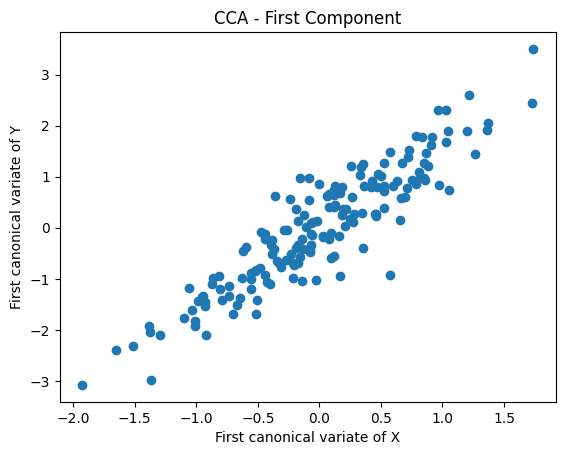

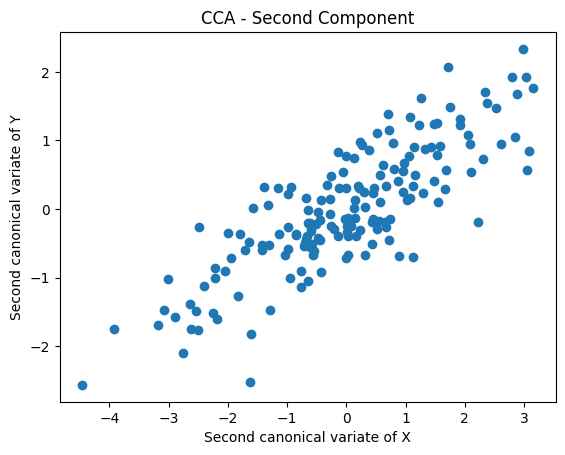

Canonical correlations: [np.float64(0.9151565653060538), np.float64(0.8271554375145934), np.float64(0.14408729363786485)]


In [ ]:
plt.scatter(X_train_c[:, 0], Y_train_c[:, 0])
plt.xlabel("First canonical variate of X")
plt.ylabel("First canonical variate of Y")
plt.title("CCA - First Component")
plt.show()

plt.scatter(X_train_c[:, 1], Y_train_c[:, 1])
plt.xlabel("Second canonical variate of X")
plt.ylabel("Second canonical variate of Y")
plt.title("CCA - Second Component")
plt.show()

print("Canonical correlations:", train_corr)

In [ ]:
print("X Weights:\n", cca.x_weights_)
print("Y Weights:\n", cca.y_weights_)

# Canonical loadings
x_loadings = np.corrcoef(X_train.T, X_train_c.T)[:4, 4:]
y_loadings = np.corrcoef(Y_train.T, Y_train_c.T)[:3, 3:]

print("X Loadings:\n", x_loadings)
print("Y Loadings:\n", y_loadings)

print("Strongest X variable for component 1:",
      X.columns[np.argmax(abs(x_loadings[:, 0]))])

print("Strongest Y variable for component 1:",
      Y.columns[np.argmax(abs(y_loadings[:, 0]))])

X Weights:
 [[ 0.43334102 -0.54589807 -0.39651364]
 [ 0.76354193  0.64499288 -0.00756238]
 [ 0.47384715 -0.53130528  0.48722783]
 [-0.06847009  0.06077972  0.77802878]]
Y Weights:
 [[-0.172641    0.76747678 -0.6173933 ]
 [-0.97363387 -0.03808342  0.22491496]
 [ 0.14910456  0.63994457  0.75381614]]
X Loadings:
 [[ 0.44427462 -0.86288358 -0.04311561]
 [ 0.19893917  0.97992122  0.00557709]
 [ 0.65903296 -0.7131979   0.12946155]
 [-0.43348643  0.53076161  0.68525641]]
Y Loadings:
 [[-0.48787578  0.81911064 -0.30172005]
 [-0.99099903 -0.07641608  0.10991592]
 [ 0.81382382  0.4494215   0.36838989]]
Strongest X variable for component 1: X3
Strongest Y variable for component 1: Y2


Training canonical correlations: [np.float64(0.9151565653060538), np.float64(0.8271554375145934), np.float64(0.14408729363786485)]
Testing canonical correlations: [np.float64(0.9238458004350002), np.float64(0.8285070835321344), np.float64(-0.18398735575523897)]


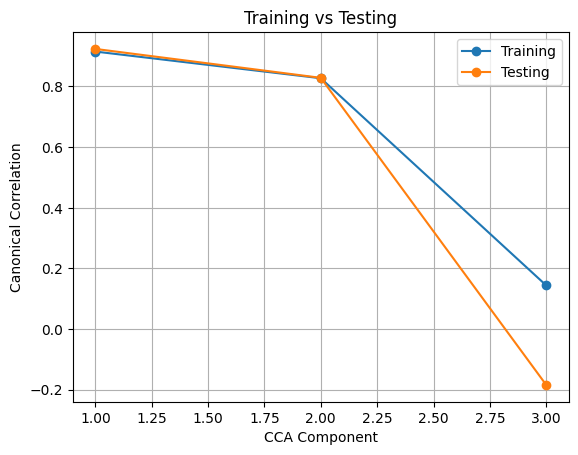

In [ ]:
print("Training canonical correlations:", train_corr)
print("Testing canonical correlations:", test_corr)

plt.plot(range(1, 4), train_corr, marker='o', label='Training')
plt.plot(range(1, 4), test_corr, marker='o', label='Testing')

plt.xlabel("CCA Component")
plt.ylabel("Canonical Correlation")
plt.title("Training vs Testing")
plt.legend()
plt.grid()
plt.show()